# 02 · Preprocesamiento de imágenes ASL

## Decisiones basadas en la exploración

- La carpeta de entrenamiento contiene 29 clases con 3.000 imágenes por clase; las imágenes son JPEG RGB de 200 × 200.
- El test que venía con Kaggle tiene 28 imágenes y cada una es una copia exacta de una imagen del entrenamiento. **No se usará para evaluar**.
- Crearemos particiones nuevas y estratificadas desde la carpeta de entrenamiento: 70% entrenamiento, 15% validación y 15% prueba final, con semilla fija.
- Se conservan 200 × 200 píxeles y se convierten los valores a `float32` en el rango [0, 1].
- No aplicamos aumentación todavía; en particular, no volteamos las manos, pues la transformación podría cambiar la seña.

La primera celda configura las rutas relativas al repositorio. Ejecuta en orden y revisa que las verificaciones de fuga de datos pasen.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents] if (p / "src").is_dir() and (p / "data").is_dir()), _here)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import create_stratified_splits, build_tf_dataset

# Esta carpeta contiene una subcarpeta por cada clase; no es el test oficial.
CLASS_ROOT = PROJECT_ROOT / "data" / "raw" / "asl_alphabet_train" / "asl_alphabet_train"
SEED = 42
IMAGE_SIZE = (200, 200)
BATCH_SIZE = 32

print("Raíz del proyecto:", PROJECT_ROOT)
print("Carpeta de imágenes etiquetadas:", CLASS_ROOT)
if not CLASS_ROOT.is_dir():
    raise FileNotFoundError(f"No se encontró {CLASS_ROOT}. Ajusta CLASS_ROOT a la ruta detectada en el notebook 01.")

Raíz del proyecto: C:\SOFIA\ESTUDIOS\UNIVERSIDADES\UIS\PROYECTOS GITHUB\asl-sign-language-recognition
Carpeta de imágenes etiquetadas: C:\SOFIA\ESTUDIOS\UNIVERSIDADES\UIS\PROYECTOS GITHUB\asl-sign-language-recognition\data\raw\asl_alphabet_train\asl_alphabet_train


## 1. Crear particiones estratificadas

La función verifica hashes SHA-256 antes de dividir: copias idénticas dentro de la carpeta de entrenamiento se colapsan para que una copia no quede en entrenamiento y otra en evaluación. Si los mismos bytes tienen etiquetas distintas, se detiene para que revisemos el problema.

In [2]:
splits = create_stratified_splits(
    CLASS_ROOT,
    validation_fraction=0.15,
    test_fraction=0.15,
    seed=SEED,
)

print("Clases:", splits.class_names)
print("Copias exactas removidas del conjunto de entrenamiento:", splits.duplicates_removed)
print(f"Tamaños: train={len(splits.train):,}, validation={len(splits.validation):,}, test={len(splits.test):,}")

split_counts = pd.concat([
    splits.train.assign(particion="train"),
    splits.validation.assign(particion="validation"),
    splits.test.assign(particion="test"),
]).groupby(["label", "particion"], observed=True).size().unstack(fill_value=0)
display(split_counts)

assert set(splits.train.label_id.unique()) == set(range(len(splits.class_names)))
assert set(splits.validation.label_id.unique()) == set(range(len(splits.class_names)))
assert set(splits.test.label_id.unique()) == set(range(len(splits.class_names)))
assert split_counts.nunique(axis=0).max() == 1, "El conteo no quedó equilibrado por clase."
print("Verificado: cada partición contiene todas las clases y conserva el mismo número por clase.")

Clases: ['A', 'B', 'C', 'D', 'del', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'nothing', 'O', 'P', 'Q', 'R', 'S', 'space', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Copias exactas removidas del conjunto de entrenamiento: 0
Tamaños: train=60,900, validation=13,050, test=13,050


particion,test,train,validation
label,,,
A,450,2100,450
B,450,2100,450
C,450,2100,450
D,450,2100,450
E,450,2100,450
F,450,2100,450
G,450,2100,450
H,450,2100,450
I,450,2100,450


Verificado: cada partición contiene todas las clases y conserva el mismo número por clase.


## 2. Comprobar que no hay fuga entre particiones

Comparamos rutas y hashes. El test oficial de Kaggle no se incluye porque ya se comprobó que sus imágenes duplican ejemplos de entrenamiento.

In [3]:
train_paths = set(splits.train.path)
validation_paths = set(splits.validation.path)
test_paths = set(splits.test.path)
train_hashes = set(splits.train.sha256)
validation_hashes = set(splits.validation.sha256)
test_hashes = set(splits.test.sha256)

assert not (train_paths & validation_paths or train_paths & test_paths or validation_paths & test_paths)
assert not (train_hashes & validation_hashes or train_hashes & test_hashes or validation_hashes & test_hashes)
assert not any("asl_alphabet_test" in path.replace("\\", "/") for path in train_paths | validation_paths | test_paths)
print("Verificado: rutas y hashes son disjuntos entre train, validation y test; el test duplicado de Kaggle está excluido.")

Verificado: rutas y hashes son disjuntos entre train, validation y test; el test duplicado de Kaggle está excluido.


## 3. Crear y examinar el pipeline

El pipeline lee las rutas por lote, decodifica en RGB, convierte a `float32` y normaliza a [0, 1]. No guarda una copia procesada de las imágenes ni carga todo el conjunto a memoria.

In [4]:
train_ds = build_tf_dataset(
    splits.train,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)
validation_ds = build_tf_dataset(
    splits.validation,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)
test_ds = build_tf_dataset(
    splits.test,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

images, labels = next(iter(train_ds))
print("Forma del lote de imágenes:", images.shape)
print("Forma del lote de etiquetas:", labels.shape)
print("Tipo:", images.dtype)
print("Rango del lote:", float(np.min(images.numpy())), float(np.max(images.numpy())))
assert tuple(images.shape[1:]) == (*IMAGE_SIZE, 3)
assert images.dtype == np.float32
assert float(np.min(images.numpy())) >= 0 and float(np.max(images.numpy())) <= 1
print("Verificado: imágenes RGB con forma 200×200 y valores dentro de [0, 1].")

Forma del lote de imágenes: (32, 200, 200, 3)
Forma del lote de etiquetas: (32,)
Tipo: <dtype: 'float32'>
Rango del lote: 0.0 1.0
Verificado: imágenes RGB con forma 200×200 y valores dentro de [0, 1].


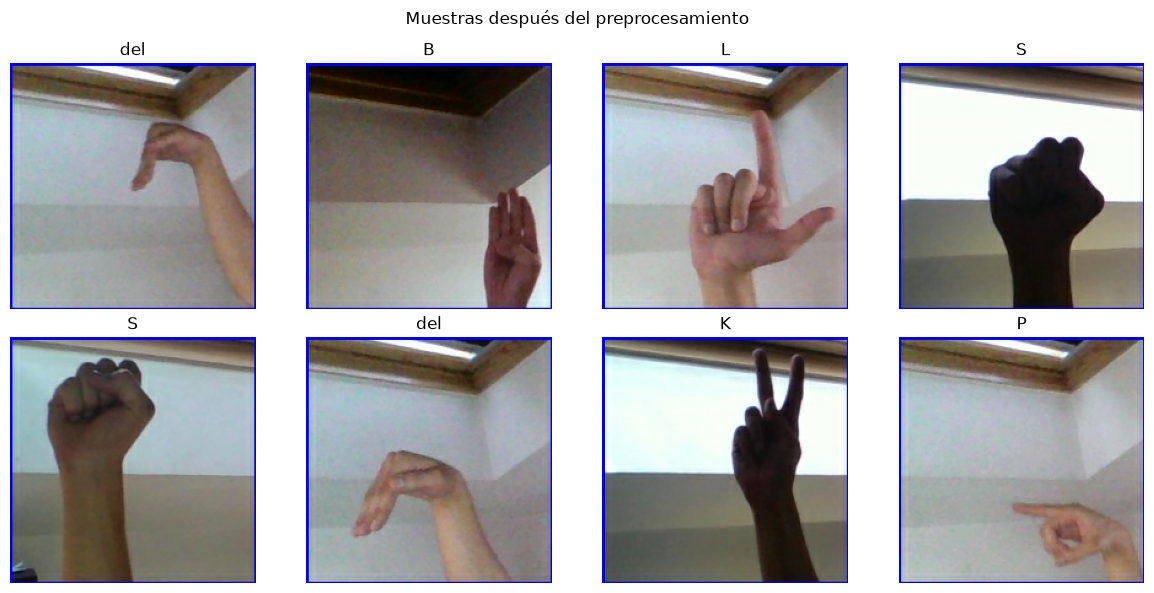

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, label_id in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(image.numpy())
    ax.set_title(splits.class_names[int(label_id.numpy())])
    ax.axis("off")
plt.suptitle("Muestras después del preprocesamiento")
plt.tight_layout()
plt.show()

## 4. Observaciones y decisiones

- Las particiones quedaron equilibradas en las 29 clases: **2.100 imágenes por clase para entrenamiento** (60.900 en total), **450 por clase para validación** (13.050) y **450 por clase para prueba** (13.050).
- El módulo no encontró duplicados exactos dentro de las carpetas de entrenamiento (`duplicates_removed = 0`).
- Las comprobaciones confirmaron que las rutas y los SHA-256 no se repiten entre las tres particiones. El test original de Kaggle quedó excluido.
- El pipeline produjo imágenes con forma `(32, 200, 200, 3)`, tipo `float32` y valores entre 0 y 1. La cuadrícula de muestras permite revisar visualmente el resultado de la decodificación.
- No se aplica aumentación todavía. Las imágenes visualmente similares que tengan bytes distintos no se han comparado de manera perceptual.

**Para la siguiente etapa:** mantener la partición `test` creada aquí aparte durante el entrenamiento y usarla solo para la evaluación final. No ajustar el preprocesamiento con base en sus resultados.